## Imports

In [1]:
%matplotlib qt

import mindmap as mm
from pathlib import Path 
import mne
import nibabel as nib

config = mm.io.read_config("../configurations/spike.yml")
fs_dir = Path(config["FS_DIR"])
mm_dir = Path(config["MM_DIR"])

## Data

In [3]:
# files
sub     = "sub-pat02"
dataset = "spike"
T1      = fs_dir/sub/"mri"/"T1.mgz"
#folder  = f"/home/admin/work/data/intra_recordings/derivatives/spike_trials/{sub}/eeg/"
#folder = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cartool-v3.80/{sub}/ses-preop/eeg/{sub}_ses-preop_task-rest_desc-spikeerp-204c-interpol-250Hz_eeg.vhdr"
folder = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cartool-v3.80/{sub}/ses-preop/eeg/{sub}_ses-preop_task-rest_desc-spikeerp-204c-250Hz_eeg.vhdr"

# data
raw   = mm.io.read_eeg(folder, dataset)
T1    = nib.load(T1)

# plot parameters
plot_kwargs = dict(
    subject=sub,
    subjects_dir=fs_dir,
    surfaces=["head", "white"],
    dig=True,
    show_axes=True,
)

## Electrode-Head alignment

#### Computing the Transformation

A transformation matrix is used to convert the position of points from one coordinate space to another. In this case, the electrodes are defined in the "head" space. If these points have been digitized, the coordinate system corresponds to the MRI space, typically referred to as "scanner RAS." <br>

MNE objects, however, exist in the "surface RAS" space, also known as FreeSurfer's space, which is called "mri" space in Python-MNE. To align the electrode positions with the "mri" space, it is necessary to compute the transformation matrix that converts coordinates from "head" space to "mri" space.

In [18]:
#trans = mm.utils.compute_transformation(sub, fs_dir, fro="head", to="mri", scale="m")
trans = mne.transforms.Transform(fro="head", to="mri")

fig = mne.viz.plot_alignment(
    raw.info,
    trans = trans,
    **plot_kwargs
)

Using pyvistaqt 3d backend.

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Using outer_skin.surf for head surface.
Channel types::	eeg: 204


In [19]:
bem  = mm_dir/sub/"fwd"/f"{sub}_hm-bem.fif"
bem  = mne.read_bem_surfaces(bem)
head = mm.utils.surf_to_polydata(bem[0]["rr"], bem[0]["tris"])

elec = mm.utils.get_ch_positions(raw)

new_points       = mne.transforms.apply_trans(trans, elec)
#new_points, _, _ = mm.utils.point_to_plane_icp_with_scaling(new_points, head, max_iterations=1)
#_, _, new_points = mm.utils.optimize_scaling_translation(new_points, head)
new_points       = mm.utils.project_points_to_surface(new_points, head)

    3 BEM surfaces found
    Reading a surface...
[done]
    Reading a surface...
[done]
    Reading a surface...
[done]
    3 BEM surfaces read


In [5]:
data     = dict(zip(raw.info["ch_names"], new_points))
montage  = mne.channels.make_dig_montage(ch_pos=data, coord_frame="head")
raw      = raw.set_montage(montage)
identity = mne.transforms.Transform(fro="head", to="mri")

fig = mne.viz.plot_alignment(
    raw.info,
    trans = identity,
    **plot_kwargs
)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
Using outer_skin.surf for head surface.
Channel types::	eeg: 204


## Interpolate bad channels

In [8]:
raw.info["bads"].append("7")
raw.interpolate_bads()

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 88.7 mm
Computing interpolation matrix from 203 sensor positions
Interpolating 1 sensors


Condition,
Data kind,average
Timepoints,250 samples
Channels,204 channels
Number of averaged epochs,1
Time range (secs),0.0 – 0.996
Baseline (secs),off


## Visualize Fourier Spectrum

In [8]:
_ = raw.compute_psd().plot()

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).


## Compute evoked potentials


In [4]:
if dataset == "spike":
    evoked = raw.copy()

elif dataset == "intra":
    raw = raw.set_eeg_reference(["VREF"])
    evoked = raw.average()
    evoked = mne.set_eeg_reference(evoked, "average")

_ = evoked.plot()

## Preprocess evoked

In [11]:
baseline = []
notch50  = True
h_freq   = 0              # highest frequency for low pass
l_freq   = 0              # lowest frequency for high pass

# Apply baseline
if len(baseline) > 1:
    evoked.apply_baseline(baseline)

# Notch
if notch50 == True:
    evoked.filter(
        l_freq=63,
        h_freq=37,
        picks="all",
        method="fir",
    )

# Filter
if h_freq>0:
    evoked.filter(
        l_freq=None,
        h_freq=h_freq,
        picks="all",
        method="fir",
    )

if l_freq>0:
    evoked.filter(
        l_freq=l_freq,
        h_freq=None,
        picks="all",
        method="fir",
    )

# Visualize
_ = evoked.plot()

Setting up band-stop filter from 37 - 63 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 37.00
- Lower transition bandwidth: 9.25 Hz (-6 dB cutoff frequency: 32.38 Hz)
- Upper passband edge: 63.00 Hz
- Upper transition bandwidth: 15.75 Hz (-6 dB cutoff frequency: 70.88 Hz)
- Filter length: 91 samples (0.364 s)



[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


In [12]:
_ = evoked.compute_psd().plot()

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).


## Visualize Topomaps

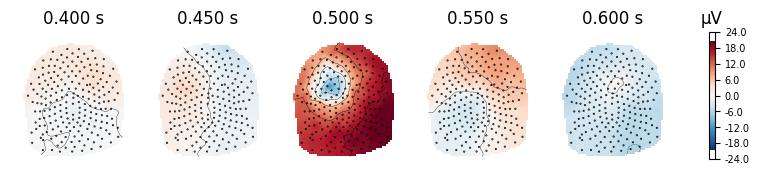

In [5]:
# time points 
times = [0.4, 0.45, 0.5, 0.55, 0.6]

evoked.plot_topomap(
    times = times,
    outlines = None,
    #sphere = None, 
    extrapolate = "local",
)


## Save processed EEG

In [14]:
# save source space
folder = Path(config["MM_DIR"])/sub/"eeg"

if folder.exists() == False:
        folder.mkdir(parents=True)

print(f"Save EEG for subject: {sub}")
evoked.save(folder/f"{sub}_ave.fif", overwrite=True)

Save EEG for subject: sub-pat02
Overwriting existing file.
